# Этап 2. Подбор сил рычагов

**Вопрос этапа:** при каких силах рычагов L3–L6 получаются лучшие компромиссы между дефицитом, ценовой нагрузкой, очередями и затратами и какие 6–8 стратегий-финалистов идут на проверку устойчивости (этап 3).

**Правила оформления кода проекта:** всё, что выводится на экран (print, заголовки и оси графиков, названия столбцов и строк таблиц), - на английском; на русском только markdown и комментарии. Ячейки дольше 10 минут помечены `# WARNING` в первой строке.

## Решения по итогам скрининга (зафиксированы до прогонов)

### 1. L2 (запрет экспорта) всегда включён

Каждая комбинация с L2 сравнивалась с той же комбинацией без L2 (скрининг, 16 пар × 3 шока):
* K0 при включённом L2 ниже на 20–99.9%;
* худший побочный эффект - K4 выше на 4–6% (при потолке цены продаётся больше бензина по цене выше 1) или K5 выше до 15% при слабом шоке;
* по остальным KPI L2 не хуже.

То есть L2 практически доминирует, и держать его как переменную - значит удваивать число прогонов ради заранее известного ответа. Поэтому на этапах 2–5 L2 всегда включён.

**Ограничение для отчёта:** в модели запрет экспорта ничего не стоит - издержки (потеря экспортной выручки НПЗ, торговые отношения, сигнал рынку) в K0–K5 не входят. Вывод «L2 всегда выгоден» верен только внутри модели; в реальности регулятору нужно сопоставить его выгоду с этими издержками.

### 2. L5 (лимит на заправку): диапазон 30–70 л вместо 10–70 л

* Лимит 30 л почти всегда добавлял 6–15 ч очередей на машину: обычная заправка - около 40 л (бак 50 л, порог 20%), поэтому меньший лимит означает больше заездов на АЗС. Комбинации «только L5» и «L3+L5» доминируемы при всех трёх шоках.
* Но при сильном шоке (0.7) L5 снижает K0 на 42% (главный эффект): лимит сдерживает накопление бензина в канистрах.
* Лимит ниже 30 л заведомо хуже (ещё больше заездов), поэтому его не исследуем. Верхняя граница 70 л = бак + канистра, при ней лимит не действует. Вопрос этапа 2: есть ли лимит в 40–60 л, который сдерживает канистры, не создавая очередей.

### 3. L6 (потолок цены): два блока LHS

* Потолок 1.1 при сильном шоке слишком жёсткий для имеющегося предложения: при шоке 0.7 даже L2+L3+L4+L6 давал K0 больше, чем без мер. Работает ли потолок, решает его взаимодействие с L3 и L4 (L4×L6 η² = 0.70, L3×L4×L6 η² = 0.32 по K0 при шоке 0.45), поэтому потолок и силы L3, L4 подбираем совместно.
* «Потолка нет» нельзя изобразить краем непрерывного диапазона: без потолка цена при шоке 0.7 доходит до 4, а потолок 2.0 при слабом предложении ещё действует. Поэтому два блока:
  * **блок A** - 60 точек, потолок 1.0–2.0, четыре силы (L3, L4, L5, L6);
  * **блок B** - 40 точек без потолка, три силы (L3, L4, L5).

Плюс две опорные точки: «без мер» (для нормировки K0 и K4 на тех же seed) и «только L2» (минимальное вмешательство).

### 4. Четыре оси отбора финалистов вместо шести K

| Ось | Что входит | Почему так |
|---|---|---|
| физический дефицит | K0, L | главный показатель кризиса |
| ценовая нагрузка | K4, m.u. | K1 и K4 оба определяются ценой: в скрининге их корреляция по 32 комбинациям 0.98–0.998 (в лог-шкале 0.998–0.9995). Две почти одинаковые оси не добавляют информации, но увеличивают число недоминируемых точек. K1 остаётся в таблицах |
| очереди | K5 сверх фона без шока, ч на машину | фон (~2.7 ч/машину за год) есть и без кризиса; сравниваем то, что добавляют шок и меры |
| затраты мер | K2 + c3 · K3, m.u., c3 = 0.25 | обе величины - цена мер для бюджета и общества. Сводим их в деньги через c3 (номинал 0.25 m.u./L - примерно середина диапазона 0.05–0.5). Чувствительность к c3 - на этапе 4, без прогонов |

Почему меньше осей: при шести критериях почти всё недоминируемо - в скрининге 30 из 32 комбинаций были недоминируемы хотя бы при одном шоке, фронт ничего не отсеивал. С четырьмя осями фронт отбирает, а смысл каждой оси понятен для доклада.

### 5. Два ответа в итоге
* **стратегия под шок** - регулятор видит, какой НПЗ и насколько пострадал, и выбирает меры под эту силу шока;
* **одна устойчивая стратегия** для всех трёх шоков - если силу шока заранее не знают. На этом этапе это кандидат minimax: стратегия, у которой худшая по трём шокам оценка наименьшая.

## План этапа
* 100 точек LHS (60 + 40) + 2 опорные × 3 шока × 3 seed пула `levels` = **918 прогонов**, порядок по seed (при остановке остаётся сбалансированный план);
* LHS с максимально разнесёнными точками (maximin): из 500 случайных латинских гиперкубов берём тот, где минимальное расстояние между точками наибольшее;
* метамодель: квадратичная регрессия с парными взаимодействиями (log K0, log K4, K5 в исходной шкале), проверка перекрёстной проверкой, карты-срезы;
* недоминируемые точки по 4 осям при каждом шоке, выбор 6–8 финалистов, силы округляются до шага слайдеров модели.

## 2.0. Окружение

In [1]:
# %pip install statsmodels psutil scipy   # если не установлены

import json, hashlib, itertools, math, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.spatial.distance import pdist

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import abm_runner as ar

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
GRAY = "#b9b7b0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "axes.prop_cycle": plt.cycler(color=PAL)})

# --- пути: как в ноутбуках 0 и 1 ---
NETLOGO_HOME = r"C:\Program Files\NetLogo 7.0.4"
MODEL_PATH   = Path("refinery_shock_abm.nlogox")
OUT_DIR      = Path("results")

PREP  = json.loads((OUT_DIR / "prep_summary.json").read_text(encoding="utf-8"))
SCRS  = json.loads((OUT_DIR / "screening_summary.json").read_text(encoding="utf-8"))
SEEDS = json.loads((OUT_DIR / "seeds.json").read_text(encoding="utf-8"))["pools"]
sha = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
assert sha == PREP["model_sha256"], "Model file changed after stage 0 - results are not comparable. Stop."
print("Model unchanged since stage 0:", sha[:16], "| NetLogo", PREP["netlogo_version"])

Model unchanged since stage 0: 2b246166dc0c1182 | NetLogo 7.0.4


## 2.1. Модуль пакетного запуска

Новая версия `batch_runner.py` заменяет прежнюю (совместима с ноутбуком 1): исправление с принудительным завершением процессов пула в конце, весь вывод на английском.

In [2]:
import importlib, batch_runner as br
importlib.reload(br)

# --- решения этапа 2 ---
R           = 3
SEEDS_LV    = SEEDS["levels"][:R]
SHOCKS      = PREP["shock_levels"]                      # [0.2, 0.45, 0.7]
N_A, N_B    = 60, 40                                    # блок A (с потолком) и блок B (без потолка)
LHS_SEED    = 20261120                                  # генератор плана LHS (не seed модели)
N_CAND      = 500                                       # кандидатов для maximin
C3_NOM      = 0.25                                      # m.u. на литр низкосортного бензина
MAX_FINAL   = 8
SIM_TOL     = 0.15                                      # близость стратегий в нормированном пространстве сил

# силы рычагов: имя слайдера -> (короткое имя столбца, нижняя граница, верхняя граница, шаг слайдера)
LV = {
    "L3-share-naphtha":     ("L3_share",  0.0, 0.5, 0.05),
    "L4-import-limit":      ("L4_limit",  0.0, 0.3, 0.01),
    "L5-liters-per-fillup": ("L5_liters", 30,  70,  5),     # 70 = бак + канистра: лимит не действует
    "L6-price-cap":         ("L6_cap",    1.0, 2.0, 0.05),
}
SHORT = {k: v[0] for k, v in LV.items()}
N_CARS = PREP["constants"]["n-consumers"]
K5_BG  = SCRS["k5_background"]                          # фон очередей без шока, машино-ч за год
SUBSIDY = PREP["interface_defaults"]["L4-subsidy"]

N_WORKERS = SCRS["n_workers"]                           # 2 по тесту этапа 1; можно поменять вручную
JVM_ARGS  = ["-Xmx512m"]
CFG = {"netlogo_home": NETLOGO_HOME, "model_path": str(MODEL_PATH.resolve()), "jvmargs": JVM_ARGS,
       "jvm_path": ar.find_jvm(NETLOGO_HOME), "horizon": PREP["horizon"], "checkpoints": PREP["checkpoints"],
       "interface_defaults": PREP["interface_defaults"], "nominal_uncertain": PREP["nominal_uncertain"]}
print("levels seeds:", SEEDS_LV, "| workers:", N_WORKERS, "| K5 background:", round(K5_BG), "car-h/year")

levels seeds: [591, 763, 194] | workers: 2 | K5 background: 13675 car-h/year


## 2.2. План LHS

Латинский гиперкуб: диапазон каждой силы делится на n равных интервалов, и в каждом интервале ровно одна точка - так каждая сила покрыта равномерно при любом n. Из 500 случайных гиперкубов берём тот, где минимальное расстояние между точками наибольшее (maximin): точки не слипаются.

Переключатели: L2, L3, L4, L5 включены во всех точках (сила 0 у L3 или L4 и 70 л у L5 равносильны выключенному рычагу), L6 включён в блоке A и выключен в блоке B.

In [3]:
def lhs_maximin(n, d, rng, n_cand=N_CAND):
    # лучший из n_cand латинских гиперкубов по минимальному попарному расстоянию
    best, best_d = None, -1
    for _ in range(n_cand):
        u = np.column_stack([(rng.permutation(n) + rng.random(n)) / n for _ in range(d)])
        dmin = pdist(u).min()
        if dmin > best_d:
            best, best_d = u, dmin
    return best, best_d

rng = np.random.default_rng(LHS_SEED)
names_A = list(LV)                                   # 4 силы
names_B = [k for k in LV if k != "L6-price-cap"]     # 3 силы
uA, dA = lhs_maximin(N_A, len(names_A), rng)
uB, dB = lhs_maximin(N_B, len(names_B), rng)

def scale(u, names):
    return {SHORT[k]: LV[k][1] + u[:, i] * (LV[k][2] - LV[k][1]) for i, k in enumerate(names)}

PA = pd.DataFrame(scale(uA, names_A)).assign(block="A", L6_on=True)
PB = pd.DataFrame(scale(uB, names_B)).assign(block="B", L6_on=False, L6_cap=np.nan)
PA["point_id"] = [f"A{i + 1:02d}" for i in range(N_A)]
PB["point_id"] = [f"B{i + 1:02d}" for i in range(N_B)]
ON = PREP["lever_on"]
ANCH = pd.DataFrame([
    {"point_id": "none", "block": "anchor", "L2_on": False, "L3_on": False, "L4_on": False, "L5_on": False, "L6_on": False},
    {"point_id": "L2_only", "block": "anchor", "L2_on": True, "L3_on": False, "L4_on": False, "L5_on": False, "L6_on": False},
]).assign(L3_share=ON["L3-share-naphtha"], L4_limit=ON["L4-import-limit"],
          L5_liters=ON["L5-liters-per-fillup"], L6_cap=ON["L6-price-cap"])
POINTS = pd.concat([ANCH, PA, PB], ignore_index=True)
for c in ["L2_on", "L3_on", "L4_on", "L5_on"]:
    POINTS[c] = POINTS[c].fillna(True).astype(bool)
POINTS["L6_on"] = POINTS["L6_on"].astype(bool)
POINTS = POINTS[["point_id", "block", "L2_on", "L3_on", "L4_on", "L5_on", "L6_on",
                 "L3_share", "L4_limit", "L5_liters", "L6_cap"]]
POINTS.to_csv(OUT_DIR / "design_levels_points.csv", index=False, encoding="utf-8-sig")
print(f"block A: {N_A} points, min distance {dA:.3f} | block B: {N_B} points, min distance {dB:.3f}")
POINTS.head(6).round(3)

block A: 60 points, min distance 0.194 | block B: 40 points, min distance 0.144


,point_id,block,L2_on,L3_on,L4_on,L5_on,L6_on,L3_share,L4_limit,L5_liters,L6_cap
0,none,anchor,False,False,False,False,False,0.150,0.100,30.000,1.100
1,L2_only,anchor,True,False,False,False,False,0.150,0.100,30.000,1.100
2,A01,A,True,True,True,True,True,0.454,0.097,63.629,1.423
3,A02,A,True,True,True,True,True,0.195,0.081,46.301,1.838
4,A03,A,True,True,True,True,True,0.049,0.190,38.170,1.587
5,A04,A,True,True,True,True,True,0.486,0.208,49.649,1.397


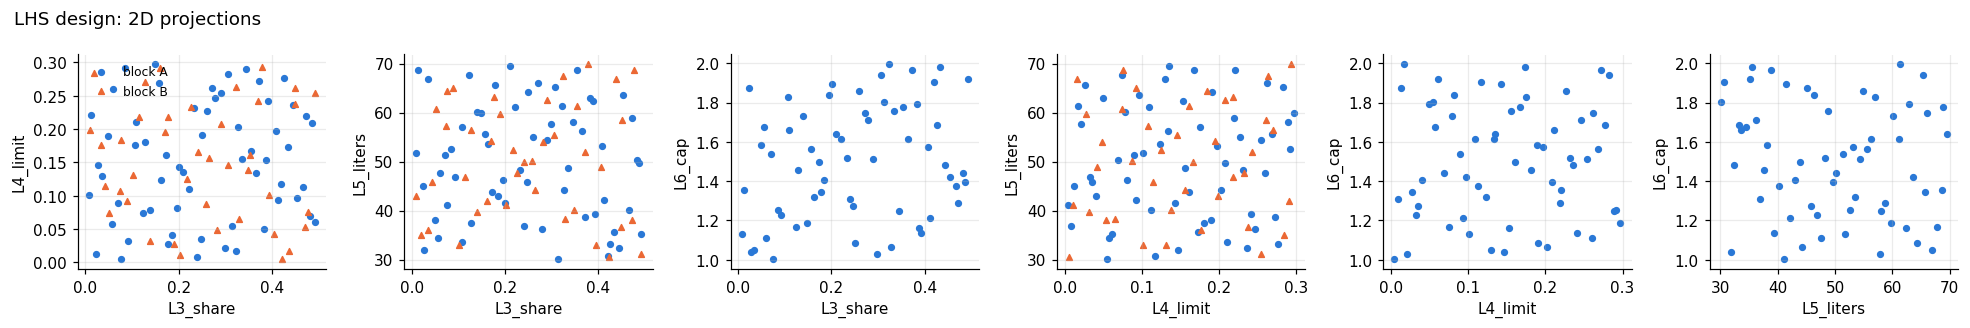

In [4]:
# покрытие плана: двумерные проекции блока A
pairs = list(itertools.combinations(["L3_share", "L4_limit", "L5_liters", "L6_cap"], 2))
fig, axes = plt.subplots(1, len(pairs), figsize=(18, 3))
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(PA[x], PA[y], s=14, color=PAL[0], label="block A")
    if y != "L6_cap" and x != "L6_cap":
        ax.scatter(PB[x], PB[y], s=14, color=PAL[1], marker="^", label="block B")
    ax.set_xlabel(x); ax.set_ylabel(y)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("LHS design: 2D projections", x=0.01, ha="left")
plt.tight_layout(); plt.show()

In [5]:
def make_job(p, shock, seed, rep):
    params = {"L2-export-ban?": bool(p.L2_on), "L3-quality-relax?": bool(p.L3_on), "L4-import?": bool(p.L4_on),
              "L5-fillup-limit?": bool(p.L5_on), "L6-price-cap?": bool(p.L6_on),
              "L3-share-naphtha": float(p.L3_share), "L4-import-limit": float(p.L4_limit),
              "L5-liters-per-fillup": float(p.L5_liters),
              "L6-price-cap": float(p.L6_cap) if p.L6_on else ON["L6-price-cap"],
              "L4-subsidy": SUBSIDY, "shock-depth": shock}
    return {"run_id": f"levels|{p.point_id}|sd={shock}|seed={seed}", "stage": "levels",
            "point_id": p.point_id, "block": p.block, "shock": shock, "seed": int(seed), "rep": rep,
            "params": params, "uncertain": None}

JOBS = [make_job(p, sh, s, r) for r, s in enumerate(SEEDS_LV, 1) for sh in SHOCKS for p in POINTS.itertuples()]
DESIGN = pd.DataFrame([{k: v for k, v in j.items() if k not in ("params", "uncertain")} for j in JOBS])
assert DESIGN.run_id.is_unique
DESIGN.to_csv(OUT_DIR / "design_levels.csv", index=False, encoding="utf-8-sig")
est_h = len(JOBS) * 26 / N_WORKERS / 3600
print(f"jobs: {len(JOBS)} | estimated time at ~26 s/run on {N_WORKERS} workers: ~{est_h:.1f} h")

jobs: 918 | estimated time at ~26 s/run on 2 workers: ~3.3 h


## 2.3. Запуск

Результаты дописываются в `results/levels.csv`; при обрыве ячейку можно просто запустить снова. Перед запуском закрыть браузер и тяжёлые программы, ноутбук на зарядке. Время оценено по скринингу (L6 почти во всех точках, такие прогоны медленнее - ~26 с).

In [6]:
# WARNING This cell takes approximately 200 minutes to run (918 runs on 2 workers)
link = ar.make_link(CFG) if N_WORKERS == 1 else None
RES = br.run_jobs(JOBS, CFG, OUT_DIR / "levels.csv", n_workers=N_WORKERS, link=link, log_every=60)
print(RES.groupby("shock").size().rename("runs"))

20:09:16 already done: 8, remaining: 910
20:09:16 start: 910 runs, workers: 2


20:10:16 ... working, 0/910
20:10:30 1/910 | 1 min | 49 runs/h | ETA ~1121 min | errors 0
20:11:41 7/910 | 2 min | 174 runs/h | ETA ~311 min | errors 0
20:12:59 13/910 | 4 min | 210 runs/h | ETA ~257 min | errors 0
20:14:07 19/910 | 5 min | 235 runs/h | ETA ~227 min | errors 0
20:15:14 25/910 | 6 min | 251 runs/h | ETA ~211 min | errors 0
20:16:31 31/910 | 7 min | 257 runs/h | ETA ~205 min | errors 0
20:17:41 39/910 | 8 min | 278 runs/h | ETA ~188 min | errors 0
20:18:45 49/910 | 9 min | 310 runs/h | ETA ~167 min | errors 0
20:19:50 61/910 | 11 min | 347 runs/h | ETA ~147 min | errors 0
20:20:53 71/910 | 12 min | 367 runs/h | ETA ~137 min | errors 0
20:21:56 79/910 | 13 min | 374 runs/h | ETA ~133 min | errors 0
20:22:56 88/910 | 14 min | 386 runs/h | ETA ~128 min | errors 0
20:24:01 95/910 | 15 min | 386 runs/h | ETA ~127 min | errors 0
20:25:08 103/910 | 16 min | 389 runs/h | ETA ~124 min | errors 0
20:26:10 108/910 | 17 min | 384 runs/h | ETA ~125 min | errors 0
20:27:11 115/910 | 1

## 2.4. Контроль полноты

In [7]:
RES = br.read_results(OUT_DIR / "levels.csv")
RES = RES[RES.run_id.isin(DESIGN.run_id)].copy()
missing = len(DESIGN) - len(RES)
print(f"completed {len(RES)} of {len(DESIGN)}, missing {missing}")
print("error file:", "present - check it" if (OUT_DIR / "levels.errors.csv").exists() else "none")
reps_done = RES.groupby("seed").size()
print("runs per seed:", reps_done.to_dict())
print(f"run time: mean {RES.sec.mean():.1f} s, median {RES.sec.median():.1f} s, max {RES.sec.max():.1f} s")

completed 918 of 918, missing 0
error file: none
runs per seed: {194: 306, 591: 306, 763: 306}
run time: mean 14.8 s, median 13.2 s, max 51.5 s


## 2.5. Отклики и четыре оси

* `K5_excess` = (K5 − фон без шока) / число машин, ч на машину за год;
* `COST` = K2 + c3 · K3 (m.u.), c3 = 0.25; K2 уже в m.u. при субсидии 0.25;
* средние по трём seed - по точке и шоку (`CELL`); относительные K0 и K4 - к точке «без мер» при том же шоке.

Ячейка также проверяет на новых данных, что K1 и K4 по-прежнему почти пропорциональны (обоснование объединения в одну ось).

In [8]:
RES["K5_excess"] = (RES.K5_hours - K5_BG) / N_CARS
RES["COST"] = RES.K2 + C3_NOM * RES.K3_volume
RES["import_volume"] = RES.K2 / SUBSIDY

AXES = ["K0", "K4", "K5_excess", "COST"]
AX_LABEL = {"K0": "K0 physical shortage, L", "K4": "K4 consumer overpayment, m.u.",
            "K5_excess": "K5 queues above background, h/car", "COST": "K2 + c3*K3 policy cost, m.u."}
VALS = ["K0", "K0@90", "K1", "K2", "K3_volume", "K4", "K5_hours", "K5_excess", "COST", "import_volume", "price", "sec"]

CELL = RES.groupby(["point_id", "block", "shock"])[VALS].mean().reset_index()
CELL = CELL.merge(POINTS, on=["point_id", "block"])
none = CELL[CELL.point_id == "none"].set_index("shock")
CELL["K0_rel"] = CELL.K0 / CELL.shock.map(none.K0)
CELL["K4_rel"] = CELL.K4 / CELL.shock.map(none.K4)
CELL.to_csv(OUT_DIR / "levels_cells.csv", index=False, encoding="utf-8-sig")

corr = CELL.groupby("shock").apply(lambda g: pd.Series({
    "corr(K1, K4)": np.corrcoef(g.K1, g.K4)[0, 1],
    "corr(log K1, log K4)": np.corrcoef(np.log1p(g.K1), np.log1p(g.K4))[0, 1]}))
print("K1 vs K4 across design points:"); display(corr.round(4))

ref = CELL[CELL.block == "anchor"].set_index(["shock", "point_id"])[["K0", "K1", "K4", "K5_excess", "COST", "price"]]
print("Reference points:"); display(ref.round(2))

K1 vs K4 across design points:


,"corr(K1, K4)","corr(log K1, log K4)"
shock,,
0.20,0.9967,0.9999
0.45,0.9834,0.9979
0.70,0.9662,0.9964


Reference points:


,,K0,K1,K4,K5_excess,COST,price
shock,point_id,,,,,,
0.20,L2_only,49.80,243480.01,1388952.90,0.22,0.0,1.27
0.45,L2_only,10807.95,599151.43,4367029.10,0.59,0.0,1.55
0.70,L2_only,72358.13,976051.15,9203137.36,1.36,0.0,2.38
0.20,none,612.04,362772.98,2252160.76,0.13,0.0,1.30
0.45,none,39334.89,788341.34,6592768.79,0.03,0.0,2.61
0.70,none,113481.46,1176485.91,12667606.03,3.97,0.0,3.34


## 2.6. Метамодель

Для каждого шока и блока: квадратичная регрессия откликов на кодированные силы (−1…+1) со всеми парными взаимодействиями и квадратами: `log(1+K0)`, `log(1+K4)`, `K5_excess` (сырой: может быть отрицательным). Надёжность - по перекрёстной проверке: точки делятся на 5 групп, модель обучается на четырёх и предсказывает пятую (все seed точки - в одной группе). Если CV R² для K0 низкий, у дефицита пороговое поведение («хватает / не хватает предложения»), и карты ниже читаем как качественные, а финалистов выбираем по фактическим прогонам, а не по метамодели.

In [9]:
CODE = {"L3_share": "s", "L4_limit": "l", "L5_liters": "f", "L6_cap": "c"}
def coded(df):
    out = df.copy()
    for col, v in CODE.items():
        k = next(k for k in LV if SHORT[k] == col)
        lo, hi = LV[k][1], LV[k][2]
        out[v] = 2 * (df[col] - lo) / (hi - lo) - 1
    return out

def formula(vars_):
    lin = " + ".join(vars_)
    return f"y ~ ({lin})**2 + " + " + ".join(f"I({v}**2)" for v in vars_)

TARGETS = {"K0": lambda d: np.log1p(d.K0), "K4": lambda d: np.log1p(d.K4), "K5_excess": lambda d: d.K5_excess}
BLOCK_VARS = {"A": ["s", "l", "f", "c"], "B": ["s", "l", "f"]}

def cv_r2(d, f, k=5, seed=0):
    pts = d.point_id.unique()
    folds = np.array_split(np.random.default_rng(seed).permutation(pts), k)
    pred = pd.Series(index=d.index, dtype=float)
    for fold in folds:
        tr, te = d[~d.point_id.isin(fold)], d[d.point_id.isin(fold)]
        pred[te.index] = smf.ols(f, data=tr).fit().predict(te)
    return 1 - ((d.y - pred) ** 2).sum() / ((d.y - d.y.mean()) ** 2).sum()

RUNS = coded(RES.merge(POINTS, on=["point_id", "block"]))
META, fit_rows = {}, []
for b, vars_ in BLOCK_VARS.items():
    for sh in SHOCKS:
        d0 = RUNS[(RUNS.block == b) & (RUNS.shock == sh)]
        for t, fn in TARGETS.items():
            d = d0.assign(y=fn(d0))
            m = smf.ols(formula(vars_), data=d).fit()
            META[(b, sh, t)] = m
            fit_rows.append({"block": b, "shock": sh, "target": t, "R2": m.rsquared, "CV_R2": cv_r2(d, formula(vars_))})
FIT = pd.DataFrame(fit_rows).pivot_table(index=["block", "target"], columns="shock", values=["R2", "CV_R2"])
print("Metamodel fit (R2 in-sample and 5-fold CV by point):"); display(FIT.round(3))

Metamodel fit (R2 in-sample and 5-fold CV by point):


CV_R2                   R2              
shock             0.20   0.45   0.70   0.20   0.45   0.70
block target                                             
A     K0         0.020 -0.059  0.841  0.354  0.532  0.899
      K4         0.734  0.085  0.453  0.850  0.693  0.815
      K5_excess  0.532 -0.537  0.768  0.803  0.427  0.881
B     K0         0.213  0.100  0.725  0.422  0.404  0.778
      K4         0.619  0.889  0.899  0.825  0.908  0.926
      K5_excess  0.622  0.590  0.692  0.808  0.810  0.803

### Карты-срезы

Предсказание метамодели на плоскости «потолок цены × лимит импорта» при L3 = 0.25 (середина) и L5 = 70 л (лимит не действует), шоки 0.45 и 0.7; точки - фактические точки плана блока A (их значения L3 и L5 другие, они показывают, где у метамодели есть данные). Второй рисунок - блок B (без потолка): плоскость «L3 × L4».

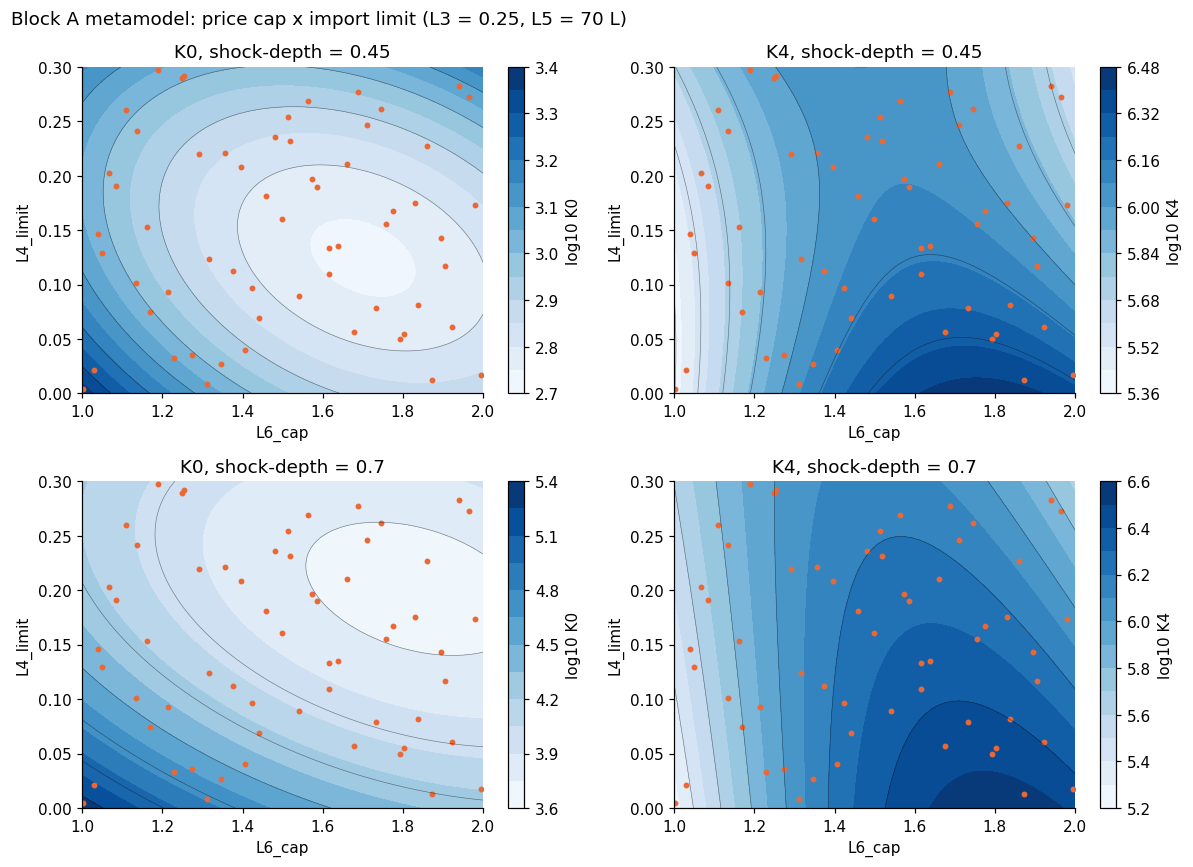

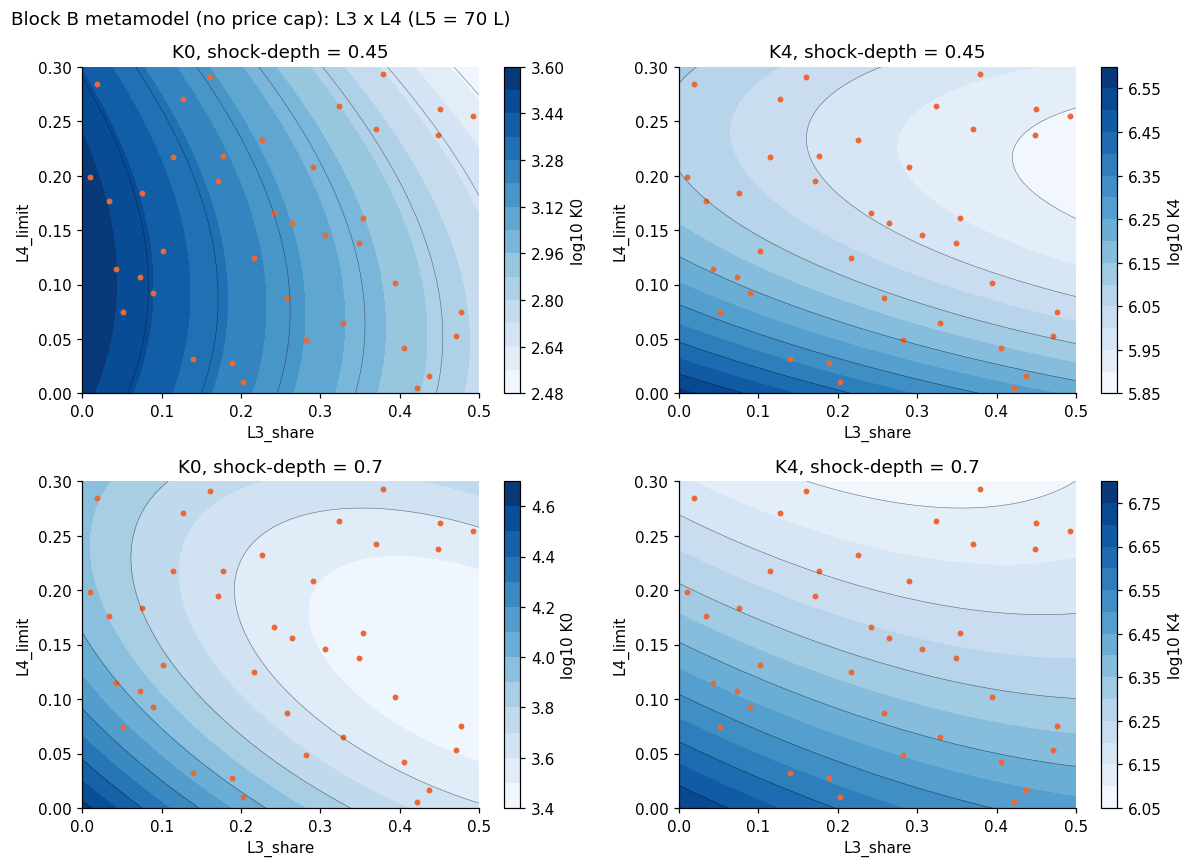

In [10]:
def slice_grid(block, sh, xcol, ycol, fixed, n=60):
    xs = np.linspace(-1, 1, n); ys = np.linspace(-1, 1, n)
    X, Y = np.meshgrid(xs, ys)
    g = pd.DataFrame({CODE[xcol]: X.ravel(), CODE[ycol]: Y.ravel()})
    for col, val in fixed.items():
        k = next(k for k in LV if SHORT[k] == col)
        g[CODE[col]] = 2 * (val - LV[k][1]) / (LV[k][2] - LV[k][1]) - 1
    out = {}
    for t in ["K0", "K4"]:
        p = META[(block, sh, t)].predict(g)
        out[t] = np.expm1(p).to_numpy().reshape(X.shape)
    def to_real(col, v):
        k = next(k for k in LV if SHORT[k] == col)
        return LV[k][1] + (v + 1) / 2 * (LV[k][2] - LV[k][1])
    return to_real(xcol, X), to_real(ycol, Y), out

def draw_slices(block, xcol, ycol, fixed, title):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for i, sh in enumerate([0.45, 0.7]):
        X, Y, out = slice_grid(block, sh, xcol, ycol, fixed)
        for j, t in enumerate(["K0", "K4"]):
            ax = axes[i, j]
            Z = np.log10(np.clip(out[t], 1, None))
            cs = ax.contourf(X, Y, Z, levels=14, cmap="Blues")
            ax.contour(X, Y, Z, levels=7, colors="#0b0b0b", linewidths=0.4, alpha=0.5)
            pts = CELL[(CELL.block == block) & (CELL.shock == sh)]
            ax.scatter(pts[xcol], pts[ycol], s=8, color=PAL[1])
            fig.colorbar(cs, ax=ax, label=f"log10 {t}")
            ax.set_title(f"{t}, shock-depth = {sh}"); ax.set_xlabel(xcol); ax.set_ylabel(ycol)
            ax.grid(False)
    fig.suptitle(title, x=0.01, ha="left"); plt.tight_layout(); plt.show()

draw_slices("A", "L6_cap", "L4_limit", {"L3_share": 0.25, "L5_liters": 70},
            "Block A metamodel: price cap x import limit (L3 = 0.25, L5 = 70 L)")
draw_slices("B", "L3_share", "L4_limit", {"L5_liters": 70},
            "Block B metamodel (no price cap): L3 x L4 (L5 = 70 L)")

## 2.7. Недоминируемые стратегии по четырём осям

Точка недоминируема при данном шоке, если ни одна другая точка не лучше или равна ей по всем четырём осям и строго лучше хотя бы по одной. Считаем по средним трёх seed, среди всех 102 точек (включая опорные). На графиках: серые - доминируемые, синие - недоминируемые блока A (с потолком), оранжевые - блока B (без потолка), ромбы - опорные точки.

Non-dominated points per shock:


block,A,B,anchor
shock,,,
0.20,36,22,2
0.45,41,20,2
0.70,51,33,1


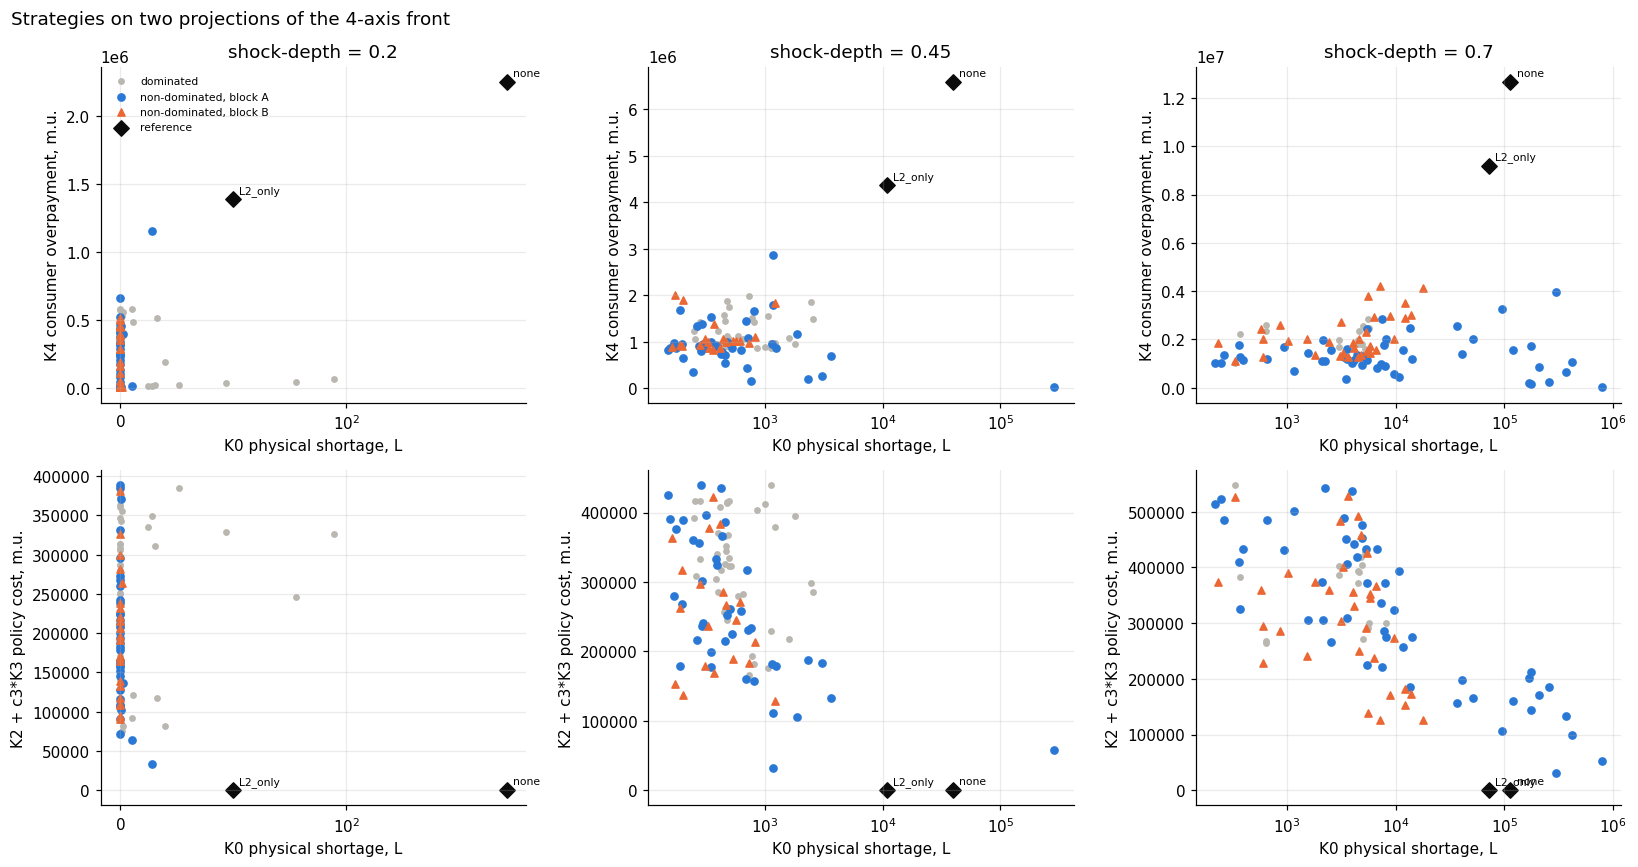

In [11]:
def nondominated(F):
    F = np.asarray(F, float)
    nd = np.ones(len(F), bool)
    for i in range(len(F)):
        nd[i] = not (np.all(F <= F[i], axis=1) & np.any(F < F[i], axis=1)).any()
    return nd

CELL["nd"] = False
for sh in SHOCKS:
    idx = CELL.index[CELL.shock == sh]
    CELL.loc[idx, "nd"] = nondominated(CELL.loc[idx, AXES])
print("Non-dominated points per shock:")
display(CELL.groupby(["shock", "block"]).nd.sum().unstack(fill_value=0))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, sh in enumerate(SHOCKS):
    c = CELL[CELL.shock == sh]
    for i, (x, y) in enumerate([("K0", "K4"), ("K0", "COST")]):
        ax = axes[i, j]
        dom = c[~c.nd]
        ax.scatter(dom[x], dom[y], s=12, color=GRAY, label="dominated")
        for b, col, mk in [("A", PAL[0], "o"), ("B", PAL[1], "^")]:
            s = c[c.nd & (c.block == b)]
            ax.scatter(s[x], s[y], s=22, color=col, marker=mk, label=f"non-dominated, block {b}")
        a = c[c.block == "anchor"]
        ax.scatter(a[x], a[y], s=50, color="#0b0b0b", marker="D", label="reference")
        for r in a.itertuples():
            ax.annotate(r.point_id, (getattr(r, x), getattr(r, y)), fontsize=7, xytext=(4, 4), textcoords="offset points")
        ax.set_xscale("symlog", linthresh=100); ax.set_xlabel(AX_LABEL[x]); ax.set_ylabel(AX_LABEL[y])
        if i == 0: ax.set_title(f"shock-depth = {sh}")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Strategies on two projections of the 4-axis front", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 2.8. Выбор финалистов

Каждая ось нормируется при каждом шоке по недоминируемым точкам этого шока: 0 = лучшее значение на фронте, 1 = худшее (доминируемые точки могут получить больше 1). Затем кандидаты в порядке приоритета:

1. **robust_minimax** - точка с наименьшей худшей по трём шокам оценкой (оценка = среднее четырёх нормированных осей, равные веса): кандидат на «одну устойчивую стратегию»;
2. **equal_weights@шок** - лучшая при равных весах на каждом шоке: кандидат на «стратегию под шок»;
3. **utopia@шок** - ближайшая к идеальной точке (все оси = 0) на каждом шоке;
4. **min_<ось>@шок** - крайние точки фронта при шоках 0.45 и 0.7 (лучшие по одной оси): нужны, чтобы на этапе 3 и 4 были стратегии с разными приоритетами.

Одинаковые точки объединяются, близкие (расстояние в нормированном пространстве сил меньше 0.15) - тоже, остаётся более приоритетная; берём не больше 8. Если кандидаты совпали и финалистов меньше 6, добираем недоминируемые точки с лучшей средней по шокам оценкой (метка `fill_best_mean_score`). «Без мер» в финалисты не входит (L2 выключен) - она остаётся опорной точкой этапа 3 вместе с «только L2». Силы финалистов округляются до шага слайдеров (L3 0.05, L4 0.01, L5 5 л, L6 0.05): рекомендацию можно выставить в модели как есть; этап 3 считает именно округлённые варианты.

Равные веса здесь - только способ выбрать компромиссных кандидатов; влияние весов разбираем на этапе 4 (таблица приоритетов, карта весов).

In [12]:
NORM = {}
for sh in SHOCKS:
    nd = CELL[(CELL.shock == sh) & CELL.nd]
    NORM[sh] = {a: (nd[a].min(), nd[a].max()) for a in AXES}

def normed(df):
    out = df.copy()
    for a in AXES:
        lo = df.shock.map({s: NORM[s][a][0] for s in SHOCKS})
        hi = df.shock.map({s: NORM[s][a][1] for s in SHOCKS})
        out["n_" + a] = (df[a] - lo) / (hi - lo).replace(0, np.nan)
        out["n_" + a] = out["n_" + a].fillna(0)
    out["score_eq"] = out[["n_" + a for a in AXES]].mean(axis=1)
    out["utopia"] = np.sqrt((out[["n_" + a for a in AXES]].clip(lower=0) ** 2).sum(axis=1))
    return out

CN = normed(CELL)
cand_pool = CN[CN.point_id != "none"]
cands = []   # (point_id, tag)
worst = cand_pool.groupby("point_id").score_eq.max()
cands.append((worst.idxmin(), "robust_minimax"))
for sh in SHOCKS:
    c = cand_pool[(cand_pool.shock == sh) & cand_pool.nd]
    cands.append((c.loc[c.score_eq.idxmin(), "point_id"], f"equal_weights@{sh}"))
for sh in SHOCKS:
    c = cand_pool[(cand_pool.shock == sh) & cand_pool.nd]
    cands.append((c.loc[c.utopia.idxmin(), "point_id"], f"utopia@{sh}"))
for sh in [0.45, 0.7]:
    c = cand_pool[(cand_pool.shock == sh) & cand_pool.nd]
    for a in AXES:
        cands.append((c.loc[c[a].idxmin(), "point_id"], f"min_{a}@{sh}"))

# нормированные силы: для близости стратегий (отсутствие потолка = отдельное измерение)
def lever_vec(pid):
    # выключенный рычаг = его «нулевая» сила: L3, L4 -> 0, L5 -> 70 л (лимит не действует)
    p = POINTS.set_index("point_id").loc[pid]
    eff = {"L3_share": p.L3_share if p.L3_on else 0.0, "L4_limit": p.L4_limit if p.L4_on else 0.0,
           "L5_liters": p.L5_liters if p.L5_on else 70.0}
    v = [(eff[SHORT[k]] - LV[k][1]) / (LV[k][2] - LV[k][1]) for k in names_B]
    v += [(p.L6_cap - 1.0) / 1.0 if p.L6_on else 0.0, 0.0 if p.L6_on else 1.0]
    return np.array(v, float)

final, tags = [], {}
for pid, tag in cands:
    if pid in tags:
        tags[pid].append(tag); continue
    close = [f for f in final if np.linalg.norm(lever_vec(f) - lever_vec(pid)) < SIM_TOL]
    if close:
        tags[close[0]].append(f"{tag} (merged {pid})"); continue
    if len(final) < MAX_FINAL:
        final.append(pid); tags[pid] = [tag]

# если финалистов меньше 6 (кандидаты совпали), добираем недоминируемые точки с лучшей средней по шокам оценкой
MIN_FINAL = 6
mean_score = cand_pool[cand_pool.nd].groupby("point_id").score_eq.mean().sort_values()
for pid in mean_score.index:
    if len(final) >= MIN_FINAL:
        break
    if pid in tags or any(np.linalg.norm(lever_vec(f) - lever_vec(pid)) < SIM_TOL for f in final):
        continue
    final.append(pid); tags[pid] = ["fill_best_mean_score"]

def round_step(v, step, lo, hi):
    return float(np.clip(round(v / step) * step, lo, hi))

rows = []
for i, pid in enumerate(final, 1):
    p = POINTS.set_index("point_id").loc[pid]
    r = {"strategy": f"S{i}", "point_id": pid, "block": p.block, "tags": "; ".join(tags[pid]),
         "L2_on": bool(p.L2_on), "L3_on": bool(p.L3_on), "L4_on": bool(p.L4_on), "L5_on": bool(p.L5_on),
         "L6_on": bool(p.L6_on)}
    for k, (col, lo, hi, step) in LV.items():
        on = bool(p[col.split("_")[0] + "_on"])
        r[col] = round_step(p[col], step, lo, hi) if on else np.nan
    rows.append(r)
FINAL = pd.DataFrame(rows)
print(f"Finalists: {len(FINAL)} (candidates considered: {len(cands)})")
display(FINAL)

Finalists: 8 (candidates considered: 15)


,strategy,point_id,block,tags,L2_on,L3_on,L4_on,L5_on,L6_on,L3_share,L4_limit,L5_liters,L6_cap
0,S1,A31,A,robust_minimax,True,True,True,True,True,0.00,0.22,70.0,1.35
1,S2,A15,A,equal_weights@0.2; utopia@0.2,True,True,True,True,True,0.05,0.13,65.0,1.05
2,S3,A53,A,equal_weights@0.45,True,True,True,True,True,0.00,0.10,50.0,1.15
3,S4,A41,A,equal_weights@0.7,True,True,True,True,True,0.15,0.08,60.0,1.75
4,S5,A09,A,utopia@0.45,True,True,True,True,True,0.10,0.03,45.0,1.25
5,S6,A23,A,utopia@0.7,True,True,True,True,True,0.05,0.09,50.0,1.55
6,S7,A30,A,min_K0@0.45,True,True,True,True,True,0.45,0.11,40.0,1.35
7,S8,A11,A,min_K4@0.45; min_K4@0.7,True,True,True,True,True,0.10,0.00,40.0,1.00


In [13]:
# KPI финалистов по шокам (средние трёх seed, исходные неокруглённые силы)
FK = CN[CN.point_id.isin(FINAL.point_id)].merge(FINAL[["strategy", "point_id"]], on="point_id")
show = FK.pivot_table(index="strategy", columns="shock",
                      values=["K0_rel", "K4_rel", "K5_excess", "COST", "score_eq"]).round(3)
print("Finalists: KPIs relative to 'none' (K0_rel, K4_rel), queues above background (h/car), cost (m.u.), equal-weight score:")
display(show)

best_by_shock = (CN[CN.nd & (CN.point_id != "none")].sort_values("score_eq").groupby("shock").head(1)
                 [["shock", "point_id", "score_eq", "K0_rel", "K4_rel", "K5_excess", "COST"]])
print("Preliminary answer 1 - best equal-weight strategy for each shock:"); display(best_by_shock.round(3))
rb = worst.idxmin()
print(f"Preliminary answer 2 - robust minimax strategy: {rb} (worst equal-weight score across shocks {worst.min():.3f})")
display(CN[CN.point_id == rb][["shock", "K0_rel", "K4_rel", "K5_excess", "COST", "score_eq", "nd"]].round(3))

Finalists: KPIs relative to 'none' (K0_rel, K4_rel), queues above background (h/car), cost (m.u.), equal-weight score:


COST                         K0_rel               K4_rel               K5_excess                   score_eq              
shock           0.20        0.45        0.70   0.20   0.45   0.70   0.20   0.45   0.70      0.20     0.45     0.70     0.20   0.45   0.70
strategy                                                                                                                                 
S1         74900.918  181783.283  274538.940  0.002  0.029  0.125  0.236  0.145  0.095    -0.105    0.037    1.080    0.113  0.140  0.164
S2         90970.777  183021.427  185672.341  0.000  0.077  2.240  0.108  0.040  0.020    -0.002    0.767   96.872    0.102  0.117  0.290
S3         72163.160  132907.934  133246.313  0.000  0.093  3.253  0.234  0.104  0.051    -0.113    2.054  130.797    0.109  0.108  0.354
S4        145468.137  193857.540  185721.817  0.000  0.020  0.119  0.167  0.230  0.195    -0.092    0.533    2.471    0.142  0.169  0.159
S5        108746.251  105221.753   98520.439  0.000  0.047  3.696  0.293  0.177  0.085    -0.160    2.913  142.859    0.143  0.110  0.380
S6        106844.811  160504.523  156947.282  0.000  0.017  0.324  0.210  0.219  0.203    -0.095    0.591   23.901    0.127  0.147  0.182
S7        371310.939  425656.235  431545.367  0.001  0.004  0.008  0.004  0.126  0.133     0.480    0.515    2.444    0.307  0.274  0.248
S8         63923.900   58414.954   52900.281  0.009  7.295  6.916  0.008  0.003  0.001     0.991  129.692  207.590    0.167  0.533  0.524

Preliminary answer 1 - best equal-weight strategy for each shock:


,shock,point_id,score_eq,K0_rel,K4_rel,K5_excess,COST
42,0.20,A15,0.102,0.000,0.108,-0.002,90970.777
157,0.45,A53,0.108,0.093,0.104,2.054,132907.934
122,0.70,A41,0.159,0.119,0.195,2.471,185721.817


Preliminary answer 2 - robust minimax strategy: A31 (worst equal-weight score across shocks 0.164)


,shock,K0_rel,K4_rel,K5_excess,COST,score_eq,nd
90,0.20,0.002,0.236,-0.105,74900.918,0.113,False
91,0.45,0.029,0.145,0.037,181783.283,0.140,True
92,0.70,0.125,0.095,1.080,274538.940,0.164,True


## 2.9. Итог этапа

Сохраняются финалисты с полными параметрами интерфейса (для этапа 3) и сводка. Пришлите вывод этой ячейки, таблицу качества метамодели (2.6), графики фронта (2.7) и таблицы финалистов (2.8).

In [14]:
def params_of(r):
    # полные параметры интерфейса; у выключенного рычага сила - значение модели по умолчанию
    d = PREP["interface_defaults"]
    return {"L2-export-ban?": bool(r.L2_on), "L3-quality-relax?": bool(r.L3_on), "L4-import?": bool(r.L4_on),
            "L5-fillup-limit?": bool(r.L5_on), "L6-price-cap?": bool(r.L6_on),
            "L3-share-naphtha": r.L3_share if r.L3_on else d["L3-share-naphtha"],
            "L4-import-limit": r.L4_limit if r.L4_on else d["L4-import-limit"],
            "L5-liters-per-fillup": r.L5_liters if r.L5_on else d["L5-liters-per-fillup"],
            "L6-price-cap": r.L6_cap if r.L6_on else d["L6-price-cap"], "L4-subsidy": SUBSIDY}

FINAL.to_csv(OUT_DIR / "finalists.csv", index=False, encoding="utf-8-sig")
CN.to_csv(OUT_DIR / "levels_scored.csv", index=False, encoding="utf-8-sig")
base = {k: v for k, v in PREP["interface_defaults"].items() if k != "shock-depth"}   # все переключатели off
refs = {"none": base, "L2_only": base | {"L2-export-ban?": True}}
SUMMARY = {
    "created": time.strftime("%Y-%m-%d %H:%M"), "model_sha256": sha, "R": R, "seeds": SEEDS_LV, "shocks": SHOCKS,
    "n_points": {"A": N_A, "B": N_B, "anchors": 2}, "lever_ranges": {SHORT[k]: [v[1], v[2]] for k, v in LV.items()},
    "c3_nominal": C3_NOM, "axes": AXES, "k5_background": K5_BG, "n_runs": int(len(RES)),
    "sec_per_run_mean": float(RES.sec.mean()), "n_workers": N_WORKERS,
    "nondominated_per_shock": CELL.groupby("shock").nd.sum().astype(int).to_dict(),
    "norm_ranges": {str(sh): {a: list(map(float, NORM[sh][a])) for a in AXES} for sh in SHOCKS},
    "robust_minimax": rb,
    "finalists": [{"strategy": r.strategy, "point_id": r.point_id, "tags": r.tags, "params": params_of(r)}
                  for r in FINAL.itertuples()],
    "references": refs,
}
(OUT_DIR / "levels_summary.json").write_text(json.dumps(SUMMARY, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps({k: SUMMARY[k] for k in ["n_runs", "sec_per_run_mean", "nondominated_per_shock", "robust_minimax"]},
                 indent=1, default=float))
print(FINAL[["strategy", "point_id", "tags"]].to_string(index=False))

{
 "n_runs": 918,
 "sec_per_run_mean": 14.798186195533766,
 "nondominated_per_shock": {
  "0.2": 60,
  "0.45": 63,
  "0.7": 85
 },
 "robust_minimax": "A31"
}
strategy point_id                          tags
      S1      A31                robust_minimax
      S2      A15 equal_weights@0.2; utopia@0.2
      S3      A53            equal_weights@0.45
      S4      A41             equal_weights@0.7
      S5      A09                   utopia@0.45
      S6      A23                    utopia@0.7
      S7      A30                   min_K0@0.45
      S8      A11       min_K4@0.45; min_K4@0.7
